# Entrenamiento de un modelo con las caracteristicas extraidas
-----
Carlos Francisco Montoya Urzua

21 de mayo de 2026

In [9]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [75]:
from google.colab import files
uploaded = files.upload()

Saving naranjas-22722151.webp to naranjas-22722151.webp


In [54]:
### **Código para entrenar el modelo con las características extraídas:**

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
# 1. Leer el archivo CSV con las características
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/caracteristicas_imagenes.csv')

# 2. Separar las características (X) y las etiquetas (y)
X = df.drop('etiqueta', axis=1)  # Las características (todas las columnas excepto 'etiqueta')
y = df['etiqueta']  # La etiqueta (la última columna)

# 3. Dividir los datos en conjunto de entrenamiento y conjunto de prueba (80% - 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# División con estratificación
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Estandarizar las características (normalizar los valores)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Entrenar un modelo de clasificación (por ejemplo, Random Forest)
modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

# 6. Evaluar el modelo -- prediccion
y_pred = modelo.predict(X_test)

# 7. Mostrar los resultados

print("Precisión del modelo:", accuracy_score(y_test, y_pred))
print("Reporte de clasificación:\n", classification_report(y_test, y_pred, zero_division=0))
#print(classification_report(y_test, y_pred, zero_division=0))
#print(classification_report(y_test, y_pred, labels=[0], zero_division=0))
print("Clases reales en y_test:", y_test.value_counts())
print("Clases predichas en y_pred:", pd.Series(y_pred).value_counts())

Precisión del modelo: 0.0
Reporte de clasificación:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       1.0
           1       0.00      0.00      0.00       1.0
           2       0.00      0.00      0.00       0.0
           4       0.00      0.00      0.00       0.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0

Clases reales en y_test: etiqueta
0    1
1    1
Name: count, dtype: int64
Clases predichas en y_pred: 4    1
2    1
Name: count, dtype: int64


In [68]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

In [76]:
img_path = list(uploaded.keys())[0]

img = image.load_img(img_path, target_size=(100,100))
img_array = image.img_to_array(img)/ 255.0
img_array = np.expand_dims(img_array, axis=0)

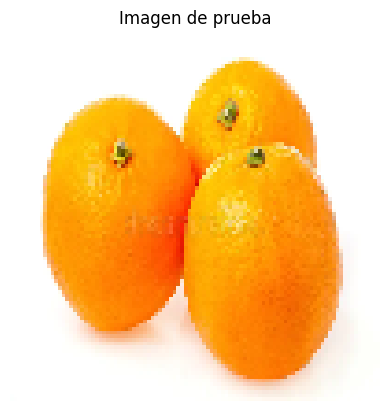

In [77]:
plt.imshow(img)
plt.axis('off')
plt.title('Imagen de prueba')
plt.show()

In [82]:
features_for_prediction = np.zeros((1,38))

pred = modelo.predict(features_for_prediction)
#clase_predicha = pred[0]
clase_predicha = pred[-1]
print(clase_predicha)


5


In [86]:
print(clase_predicha)

5


In [83]:
print(pred)

[5]


In [87]:
etiquetas = list(modelo.classes_)
etiquetas

[np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

In [89]:
#print("Clase predicha: ", etiquetas[clase_predicha])
print("Clase predicha: ", etiquetas.index(clase_predicha))

Clase predicha:  3
